# Crop Suitability Classification — Track 1 Capstone, Problem 19
**Goal:** Predict the most suitable crop (22 classes) from soil nutrients (N, P, K), pH and climate (temperature, humidity, rainfall) using foundational ML models.

**Workflow:** 1. Data loading → 2. Data quality checks → 3. EDA → 4. Preprocessing (leakage-safe) → 5. Modelling (Logistic Regression, KNN, Decision Tree) → 6. Evaluation & error analysis → 7. Save model for the Streamlit app.

**Dataset:** Crop Recommendation Dataset (Atharva Ingle, Kaggle, 2020) — 2,200 rows, 7 features, 22 crops.

In [1]:
import json, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score)
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True); os.makedirs('model', exist_ok=True)
RANDOM_STATE = 42
FEATURES = ['N','P','K','temperature','humidity','ph','rainfall']
TARGET = 'label'

## 1. Load data

In [2]:
df = pd.read_csv('data/Crop_recommendation.csv')
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Data quality checks
Missing values, duplicates, data types, class balance.

In [3]:
print('Data types:\n', df.dtypes, '\n')
print('Missing values per column:\n', df.isnull().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate feature rows (same inputs):', df.duplicated(subset=FEATURES).sum())
print('Number of crops:', df[TARGET].nunique())

Data types:
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object 

Missing values per column:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64 

Duplicate rows: 0
Duplicate feature rows (same inputs): 0
Number of crops: 22


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56


count     22.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: count, dtype: float64


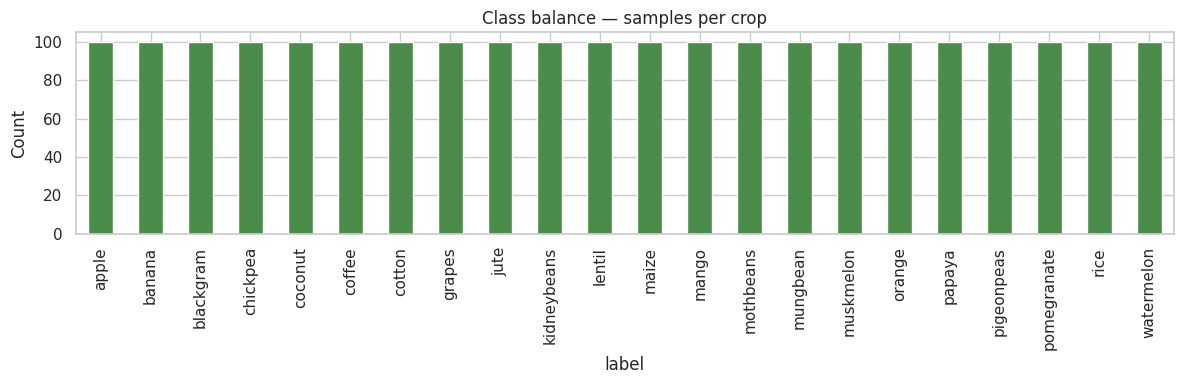

In [5]:
counts = df[TARGET].value_counts()
print(counts.describe())
plt.figure(figsize=(12,4))
counts.sort_index().plot(kind='bar', color='#4C8C4A')
plt.title('Class balance — samples per crop'); plt.ylabel('Count'); plt.tight_layout()
plt.savefig('figures/class_balance.png', dpi=150); plt.show()

**Finding:** No missing values, no duplicates, and all 22 crops have exactly 100 samples — the dataset is perfectly balanced, so accuracy is a fair headline metric and no resampling is required.

## 3. Exploratory data analysis
### 3.1 Distributions

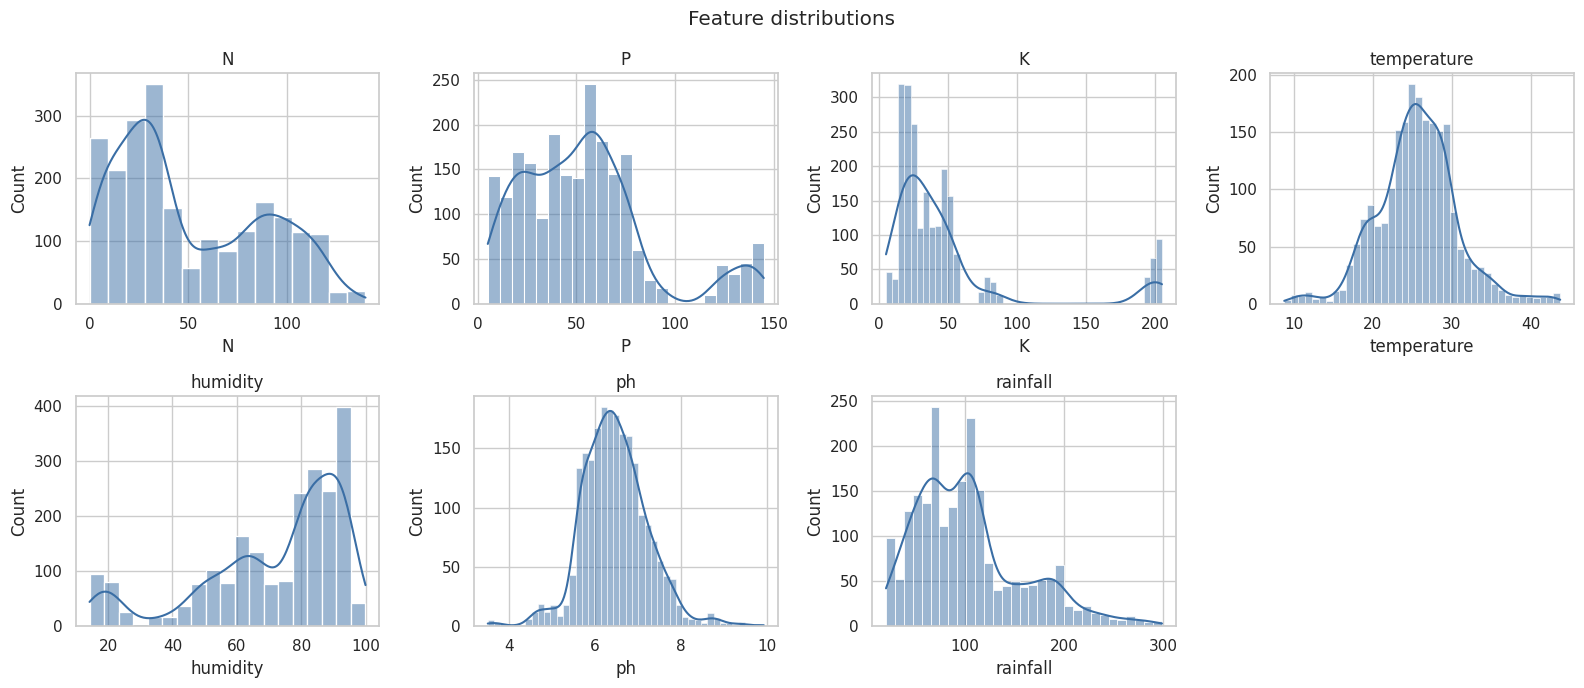

Skewness:
 N              0.51
P              1.01
K              2.38
temperature    0.18
humidity      -1.09
ph             0.28
rainfall       0.97
dtype: float64


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16,7))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.histplot(df[f], kde=True, ax=ax, color='#3A6EA5'); ax.set_title(f)
axes.ravel()[-1].axis('off')
plt.suptitle('Feature distributions'); plt.tight_layout()
plt.savefig('figures/distributions.png', dpi=150); plt.show()
print('Skewness:\n', df[FEATURES].skew().round(2))

### 3.2 Outliers (IQR rule)

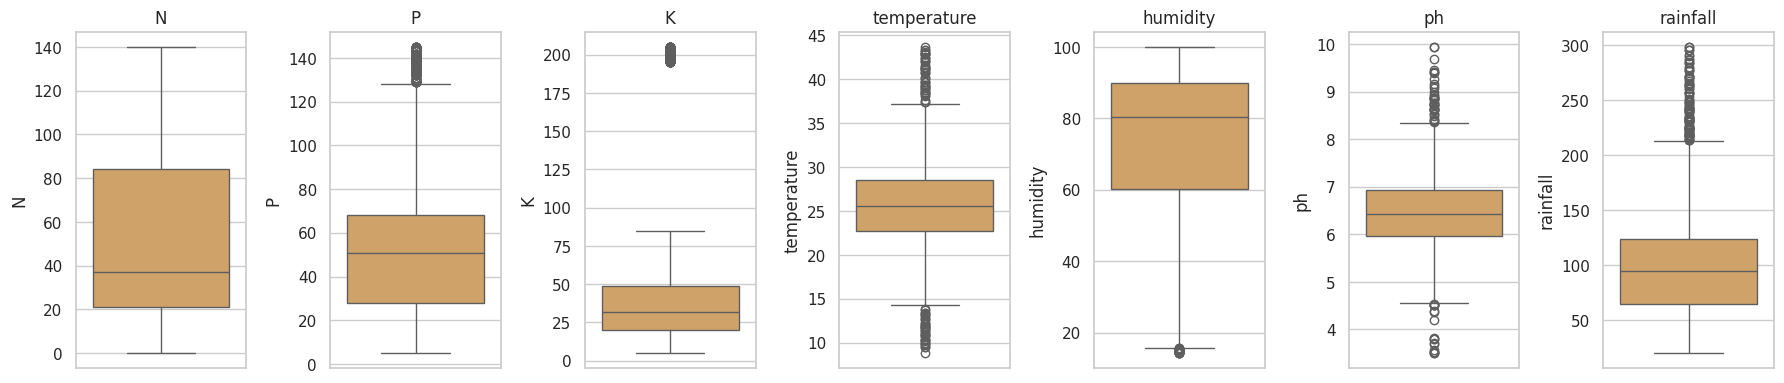

N                0
P              138
K              200
temperature     86
humidity        30
ph              57
rainfall       100
Name: IQR outliers, dtype: int64

In [7]:
fig, axes = plt.subplots(1, 7, figsize=(18,4))
for ax, f in zip(axes, FEATURES):
    sns.boxplot(y=df[f], ax=ax, color='#E0A458'); ax.set_title(f)
plt.tight_layout(); plt.savefig('figures/boxplots.png', dpi=150); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([.25,.75]); i = q3-q1
    return ((s < q1-1.5*i) | (s > q3+1.5*i)).sum()
out = pd.Series({f: iqr_outliers(df[f]) for f in FEATURES}, name='IQR outliers')
out

In [8]:
# Which crops produce the 'outliers'?
for f in ['P','K','rainfall']:
    s = df[f]; q1,q3 = s.quantile([.25,.75]); i=q3-q1
    print(f, '->', df.loc[(s<q1-1.5*i)|(s>q3+1.5*i), TARGET].value_counts().to_dict())

P -> {'apple': 70, 'grapes': 68}
K -> {'grapes': 100, 'apple': 100}
rainfall -> {'rice': 68, 'papaya': 17, 'coconut': 15}


**Finding:** The 'outliers' in P, K and rainfall belong to specific crops (e.g. grapes and apple need very high P and K; rice needs very high rainfall). They are genuine agronomic signals, not errors, so they are **kept**.

### 3.3 Relationships

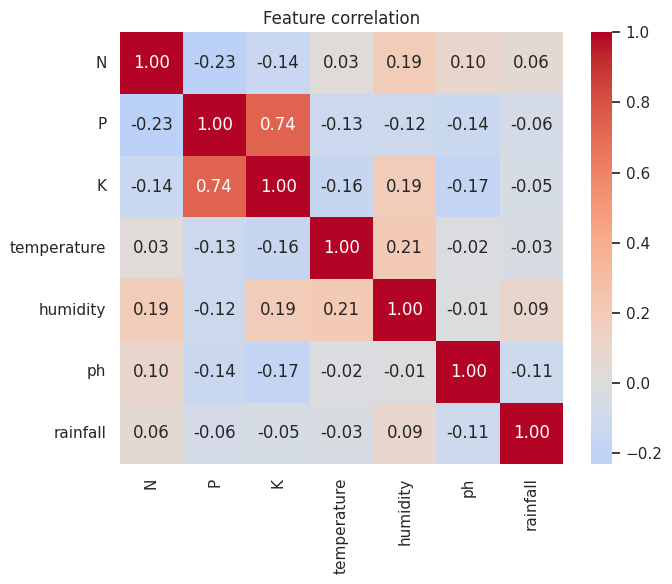

In [9]:
plt.figure(figsize=(7,6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation'); plt.tight_layout()
plt.savefig('figures/correlation.png', dpi=150); plt.show()

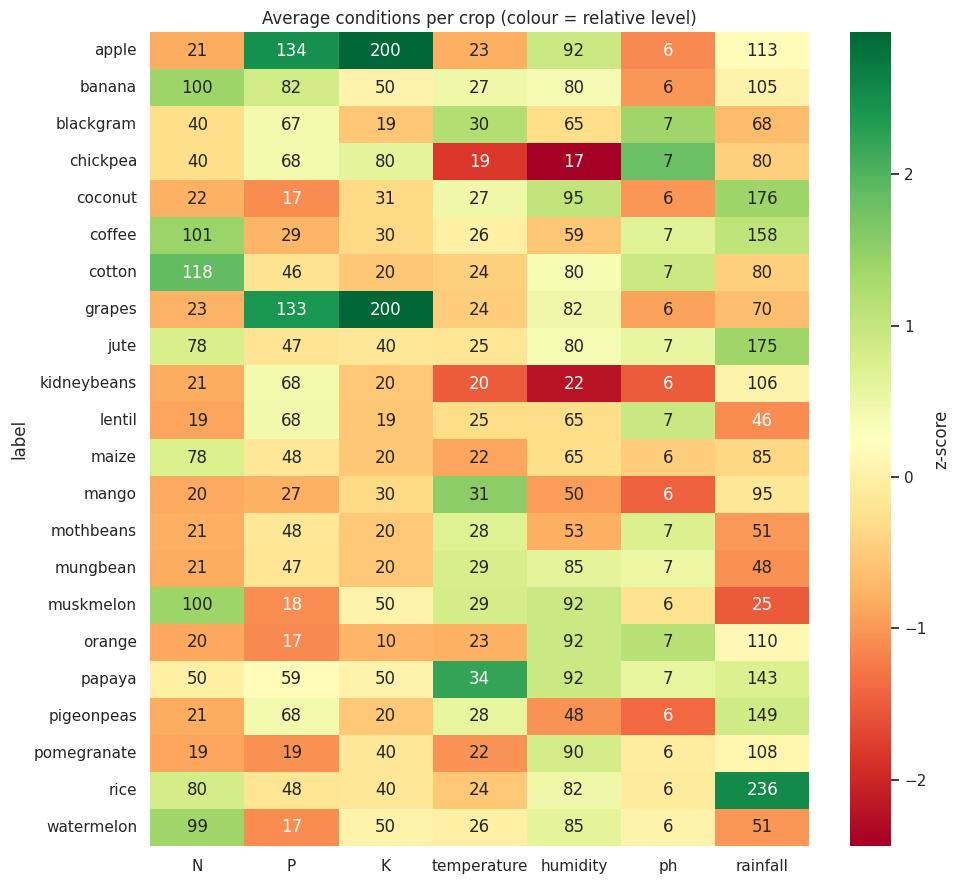

In [10]:
means = df.groupby(TARGET)[FEATURES].mean()
plt.figure(figsize=(10,9))
sns.heatmap((means-means.mean())/means.std(), cmap='RdYlGn', annot=means.round(0), fmt='g', cbar_kws={'label':'z-score'})
plt.title('Average conditions per crop (colour = relative level)'); plt.tight_layout()
plt.savefig('figures/crop_profiles.png', dpi=150); plt.show()

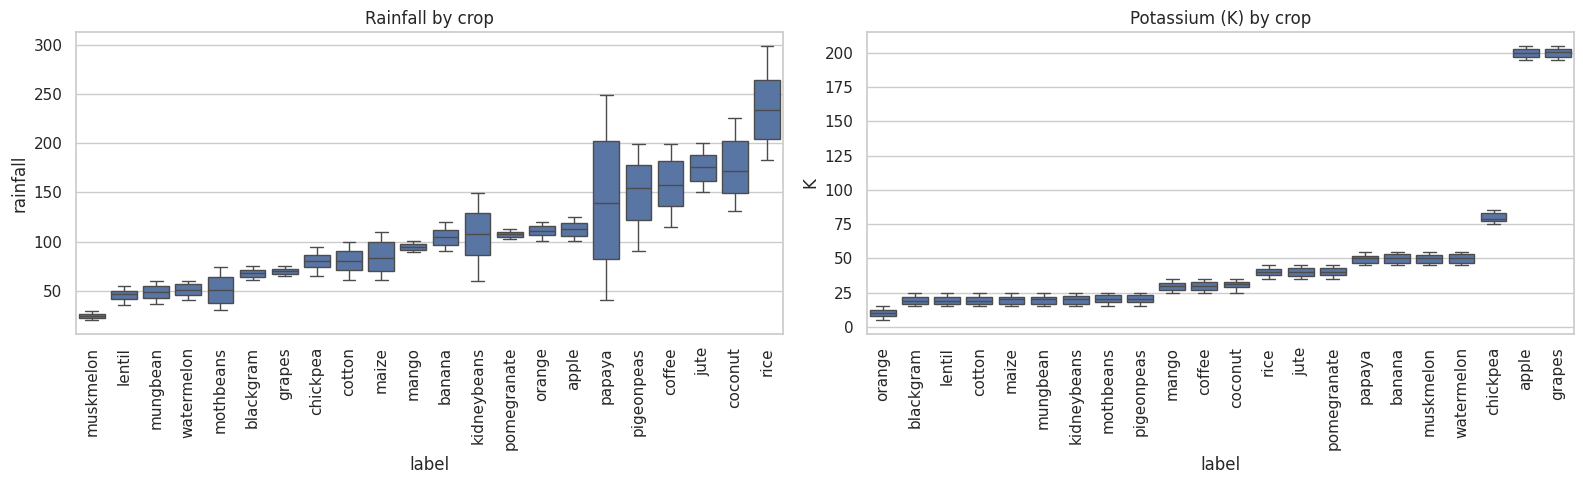

In [11]:
fig, axes = plt.subplots(1,2, figsize=(16,5))
order = means['rainfall'].sort_values().index
sns.boxplot(data=df, x=TARGET, y='rainfall', order=order, ax=axes[0]); axes[0].tick_params(axis='x', rotation=90)
order = means['K'].sort_values().index
sns.boxplot(data=df, x=TARGET, y='K', order=order, ax=axes[1]); axes[1].tick_params(axis='x', rotation=90)
axes[0].set_title('Rainfall by crop'); axes[1].set_title('Potassium (K) by crop')
plt.tight_layout(); plt.savefig('figures/rainfall_k_by_crop.png', dpi=150); plt.show()

**Findings:** Only P and K are strongly correlated (r ≈ 0.74, driven by grapes/apple). Each crop has a distinctive profile — e.g. rice and papaya need high rainfall, chickpea and kidneybeans low humidity, grapes/apple very high P & K — which suggests the classes are highly separable.

## 4. Preprocessing & leakage control
- Stratified 80/20 train/test split **before** any fitting.
- Scaling is placed **inside a Pipeline**, so the scaler is fitted only on training folds (no information from the test set leaks into training).
- Label is a crop name; scikit-learn handles string labels directly.

In [12]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
# leakage check: no identical rows shared between train and test
print('Rows shared between train & test:', pd.merge(X_train, X_test, how='inner').shape[0])

Train: (1760, 7)  Test: (440, 7)
Rows shared between train & test: 0


## 5. Modelling — three foundational models
Each model is tuned with 5-fold stratified cross-validation on the **training set only**.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
  'Logistic Regression': (Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=5000))]),
                          {'clf__C':[0.1, 1, 10, 100]}),
  'KNN': (Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier())]),
          {'clf__n_neighbors':[3,5,7,9,11], 'clf__weights':['uniform','distance']}),
  'Decision Tree': (Pipeline([('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
                    {'clf__max_depth':[5,10,15,None], 'clf__min_samples_leaf':[1,2,5]}),
}
best, rows = {}, []
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1).fit(X_train, y_train)
    best[name] = gs.best_estimator_
    p = gs.best_estimator_.predict(X_test)
    proba = gs.best_estimator_.predict_proba(X_test)
    rows.append({'Model':name, 'Best params':str(gs.best_params_),
                 'CV F1 (train)':round(gs.best_score_,4),
                 'Test Accuracy':round(accuracy_score(y_test,p),4),
                 'Test Precision':round(precision_score(y_test,p,average='macro'),4),
                 'Test Recall':round(recall_score(y_test,p,average='macro'),4),
                 'Test F1':round(f1_score(y_test,p,average='macro'),4),
                 'ROC-AUC (OvR)':round(roc_auc_score(y_test,proba,multi_class='ovr'),4)})
results = pd.DataFrame(rows).set_index('Model')
results.to_csv('model/model_comparison.csv')
results

,Best params,CV F1 (train),Test Accuracy,Test Precision,Test Recall,Test F1,ROC-AUC (OvR)
Model,,,,,,,
Logistic Regression,{'clf__C': 100},0.9776,0.9841,0.9852,0.9841,0.9840,0.9999
KNN,"{'clf__n_neighbors': 5, 'clf__weights': 'dista...",0.9680,0.9818,0.9829,0.9818,0.9816,0.9987
Decision Tree,"{'clf__max_depth': None, 'clf__min_samples_lea...",0.9858,0.9795,0.9806,0.9795,0.9794,0.9893


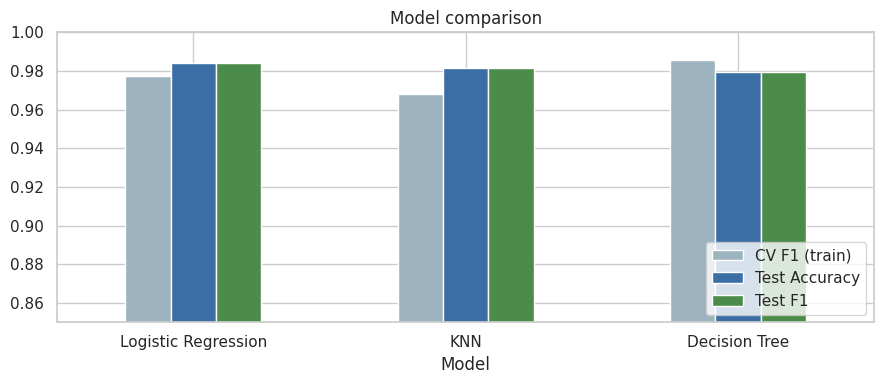

In [14]:
results[['CV F1 (train)','Test Accuracy','Test F1']].plot(kind='bar', figsize=(9,4), ylim=(0.85,1.0), color=['#9DB4C0','#3A6EA5','#4C8C4A'])
plt.title('Model comparison'); plt.xticks(rotation=0); plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=150); plt.show()

### Final model choice
We choose the model with the best **cross-validated** macro-F1 (not the test score, to avoid choosing on the test set). Ties are broken in favour of the simpler/more interpretable model.

In [15]:
best_name = results['CV F1 (train)'].idxmax()
model = best[best_name]
print('Selected model:', best_name)
print(results.loc[best_name])

Selected model: Decision Tree
Best params       {'clf__max_depth': None, 'clf__min_samples_lea...
CV F1 (train)                                                0.9858
Test Accuracy                                                0.9795
Test Precision                                               0.9806
Test Recall                                                  0.9795
Test F1                                                      0.9794
ROC-AUC (OvR)                                                0.9893
Name: Decision Tree, dtype: object


## 6. Evaluation & error analysis

In [16]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     0.800     0.889        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.950     0.950     0.950        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      0.857     0.900     0.878        20
       maize      0.952     1.000     0.976        20
       mango      1.000     1.000     1.000        20
   mothbeans      0.864     0.950     0.905        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000     1.000        20
      papaya      1.000    

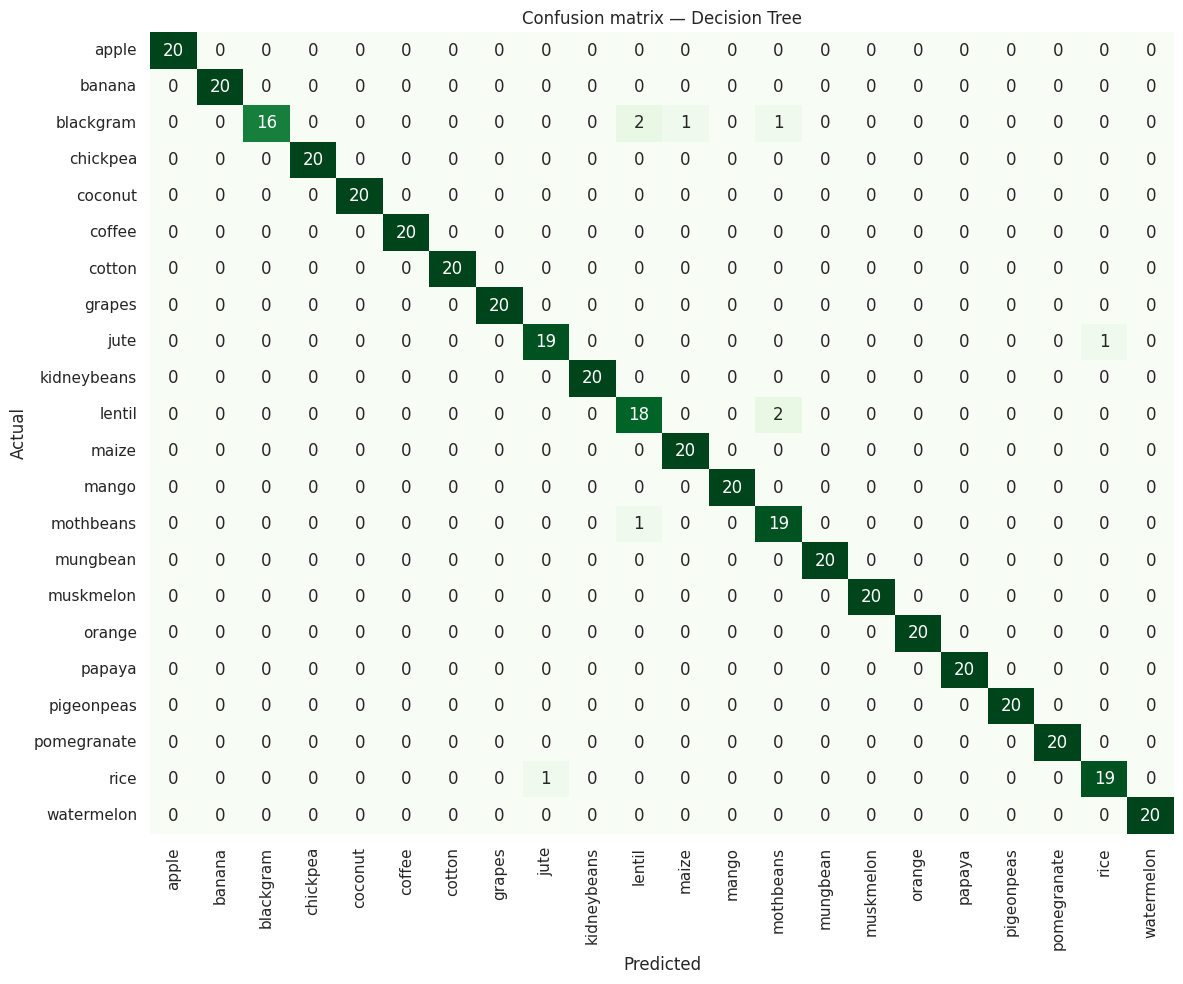

In [17]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Confusion matrix — {best_name}')
plt.tight_layout(); plt.savefig('figures/confusion_matrix.png', dpi=150); plt.show()

In [18]:
errors = X_test.copy(); errors['actual'] = y_test; errors['predicted'] = y_pred
errors = errors[errors.actual != errors.predicted]
print('Misclassified test samples:', len(errors), 'of', len(y_test))
errors

Misclassified test samples: 9 of 440


,N,P,K,temperature,humidity,ph,rainfall,actual,predicted
768,23,57,19,32.839638,67.998036,7.251001,73.404527,blackgram,lentil
789,60,59,22,31.868473,66.742175,7.191523,74.222386,blackgram,maize
838,31,58,15,28.318869,60.194614,6.167855,45.365213,lentil,mothbeans
2094,93,43,38,23.614753,86.142903,6.987333,150.235524,jute,rice
769,42,58,25,27.458536,62.900210,6.513621,69.460209,blackgram,mothbeans
754,22,55,20,33.953091,69.961000,7.423530,61.163505,blackgram,lentil
526,8,60,18,31.216300,46.018682,3.808429,53.120528,mothbeans,lentil
83,67,43,39,26.043720,84.969072,5.999969,186.753677,rice,jute
839,28,58,25,27.481865,62.048150,6.861640,37.811240,lentil,mothbeans


In [19]:
# compare misclassified pairs with the average profiles of the two crops involved
for a, p in errors[['actual','predicted']].drop_duplicates().values:
    print(f'\n{a} vs {p}:'); print(means.loc[[a,p]].round(1).to_string())


blackgram vs lentil:
              N     P     K  temperature  humidity   ph  rainfall
label                                                            
blackgram  40.0  67.5  19.2         30.0      65.1  7.1      67.9
lentil     18.8  68.4  19.4         24.5      64.8  6.9      45.7

blackgram vs maize:
              N     P     K  temperature  humidity   ph  rainfall
label                                                            
blackgram  40.0  67.5  19.2         30.0      65.1  7.1      67.9
maize      77.8  48.4  19.8         22.4      65.1  6.2      84.8

lentil vs mothbeans:
              N     P     K  temperature  humidity   ph  rainfall
label                                                            
lentil     18.8  68.4  19.4         24.5      64.8  6.9      45.7
mothbeans  21.4  48.0  20.2         28.2      53.2  6.8      51.2

jute vs rice:
          N     P     K  temperature  humidity   ph  rainfall
label                                                        
jute

### Feature relevance (permutation importance on the test set)

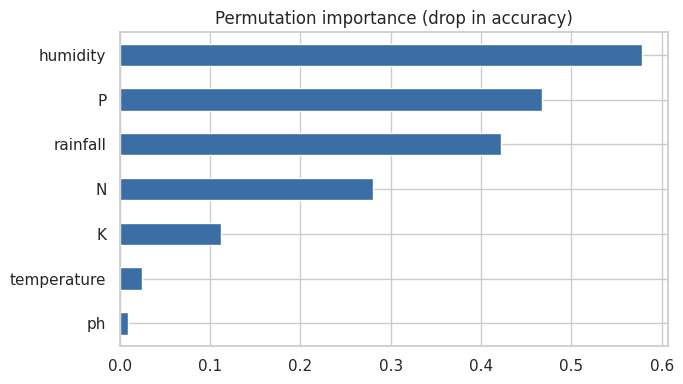

humidity       0.5780
P              0.4669
rainfall       0.4219
N              0.2802
K              0.1116
temperature    0.0252
ph             0.0090
dtype: float64

In [20]:
pi = permutation_importance(model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring='accuracy')
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind='barh', color='#3A6EA5', figsize=(7,4)); plt.title('Permutation importance (drop in accuracy)')
plt.tight_layout(); plt.savefig('figures/feature_importance.png', dpi=150); plt.show()
imp.sort_values(ascending=False).round(4)

## 7. Save the model for the Streamlit app
The whole Pipeline (scaler + classifier) is saved, so the app applies **exactly** the same preprocessing used in training.

In [21]:
joblib.dump(model, 'model/crop_model.joblib')
meta = {'model_name': best_name, 'features': FEATURES, 'classes': list(model.classes_),
        'feature_ranges': {f: [float(df[f].min()), float(df[f].max())] for f in FEATURES},
        'feature_means': {f: round(float(df[f].mean()),2) for f in FEATURES},
        'test_metrics': results.loc[best_name].drop('Best params').to_dict()}
json.dump(meta, open('model/model_meta.json','w'), indent=2)
# sanity check: reload and predict one row
m2 = joblib.load('model/crop_model.joblib')
sample = pd.DataFrame([[90,42,43,20.9,82.0,6.5,202.9]], columns=FEATURES)
print('Sample prediction:', m2.predict(sample)[0])

Sample prediction: rice


## 8. Conclusions
- The data is clean (no missing values/duplicates) and perfectly balanced across 22 crops.
- Crops have distinctive soil/climate profiles; humidity, phosphorus (P) and rainfall are the most informative features, while temperature and pH add little.
- All three foundational models exceed 97% test accuracy; the selected Decision Tree (best cross-validated F1, fully interpretable) reaches ~98% test accuracy (9 errors out of 440), mostly between agronomically similar crops.
- **Limitations:** single public dataset, synthetic-looking uniform class sizes, no location/season/soil-type information; results are an educational prototype, not agronomic advice.